# Notebook 01: Prepare data

### Load the SDF

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import PandasTools

Failed to find the pandas get_adjustment() function to patch
Failed to patch pandas - PandasTools will have limited functionality


In [2]:
df = PandasTools.LoadSDF("../data/raw/locust/HePos_Locust.SDF")
df.head()

Failed to patch pandas - unable to change molecule rendering


,NAME,ION_MODE,PRECURSOR_TYPE,COLISION_GAS,PrecursorMZ,Synonyms,InChIKey,Formula,MW,ExactMass,ID,Num Peaks,MASS SPECTRAL PEAKS,ROMol
0,​4-Phenylmethamphetamine LOW,Positive,[M+H]+,He,226.1596,"N,.alpha.-dimethyl-[1,1′-biphenyl]-4-ethanamin...",LQZHCIPFXVLYCQ-UHFFFAOYSA-N,C16H19N1,225,225.1517,,9,"167.0881 1215721.6713 """" \n183.0828 722736.995...",<rdkit.Chem.rdchem.Mol object at 0x7ad86e32f140>
1,​4-Phenylmethamphetamine MID,Positive,[M+H]+,He,226.1596,"N,.alpha.-dimethyl-[1,1′-biphenyl]-4-ethanamin...",LQZHCIPFXVLYCQ-UHFFFAOYSA-N,C16H19N1,225,225.1517,,16,"153.0728 638359.1431 """" \n155.0884 797639.0622...",<rdkit.Chem.rdchem.Mol object at 0x7ad846538a50>
2,​4-Phenylmethamphetamine HIGH,Positive,[M+H]+,He,226.1596,"N,.alpha.-dimethyl-[1,1′-biphenyl]-4-ethanamin...",LQZHCIPFXVLYCQ-UHFFFAOYSA-N,C16H19N1,225,225.1517,,18,"115.0555 610280.513 """" \n152.0651 5888619.5075...",<rdkit.Chem.rdchem.Mol object at 0x7ad846538900>
3,"1-(1,3-Diphenylpropan-2-yl)pyrrolidine LOW",Positive,[M+H]+,He,266.1909,"1-(1,3-diphenylpropan-2-yl)pyrrolidine LOW",VQECHRQHFMUVRS-UHFFFAOYSA-N,C19H23N1,265,265.183,,87,"91.0579 59401.9811 """" \n91.1335 2895.8642 """" \...",<rdkit.Chem.rdchem.Mol object at 0x7ad8465382e0>
4,"1-(1,3-Diphenylpropan-2-yl)pyrrolidine MID",Positive,[M+H]+,He,266.1909,"1-(1,3-diphenylpropan-2-yl)pyrrolidine MID",VQECHRQHFMUVRS-UHFFFAOYSA-N,C19H23N1,265,265.183,,175,"84.0842 2177.1901 """" \n86.0636 3347.0793 """" \n...",<rdkit.Chem.rdchem.Mol object at 0x7ad846538350>


### Split `NAME` into `name` and `energy`

In [3]:
df["energy"] = df.NAME.str.split().str[-1]
df["name"] = df.NAME.str.replace("\u200b", "").str.rsplit(" ", n=1).str[0]

### Drop unused columns
`ID` is empty after `LoadSDF`.

In [4]:
df = df.drop(columns=["NAME", "ID"])

### Rename columns

In [5]:
df = df.rename(columns={
    "ION_MODE": "ion_mode",
    "PRECURSOR_TYPE": "precursor_type",
    "COLISION_GAS": "collision_gas",
    "PrecursorMZ": "precursor_mz",
    "Synonyms": "synonyms",
    "InChIKey": "inchikey",
    "Formula": "formula",
    "MW": "mw",
    "ExactMass": "exact_mass",
    "Num Peaks": "n_peaks",
    "MASS SPECTRAL PEAKS": "peaks",
    "ROMol": "mol",
})

### Convert numeric columns

In [6]:
for col in ["precursor_mz", "mw", "exact_mass", "n_peaks"]:
    df[col] = pd.to_numeric(df[col])

### Reorder columns

In [7]:
df = df[["name", "energy", "inchikey", "formula", "mw", "exact_mass", "precursor_mz",
         "n_peaks", "peaks", "synonyms", "mol", "ion_mode", "precursor_type", "collision_gas"]]
df.head()

,name,energy,inchikey,formula,mw,exact_mass,precursor_mz,n_peaks,peaks,synonyms,mol,ion_mode,precursor_type,collision_gas
0,4-Phenylmethamphetamine,LOW,LQZHCIPFXVLYCQ-UHFFFAOYSA-N,C16H19N1,225,225.1517,226.1596,9,"167.0881 1215721.6713 """" \n183.0828 722736.995...","N,.alpha.-dimethyl-[1,1′-biphenyl]-4-ethanamin...",<rdkit.Chem.rdchem.Mol object at 0x7ad86e32f140>,Positive,[M+H]+,He
1,4-Phenylmethamphetamine,MID,LQZHCIPFXVLYCQ-UHFFFAOYSA-N,C16H19N1,225,225.1517,226.1596,16,"153.0728 638359.1431 """" \n155.0884 797639.0622...","N,.alpha.-dimethyl-[1,1′-biphenyl]-4-ethanamin...",<rdkit.Chem.rdchem.Mol object at 0x7ad846538a50>,Positive,[M+H]+,He
2,4-Phenylmethamphetamine,HIGH,LQZHCIPFXVLYCQ-UHFFFAOYSA-N,C16H19N1,225,225.1517,226.1596,18,"115.0555 610280.513 """" \n152.0651 5888619.5075...","N,.alpha.-dimethyl-[1,1′-biphenyl]-4-ethanamin...",<rdkit.Chem.rdchem.Mol object at 0x7ad846538900>,Positive,[M+H]+,He
3,"1-(1,3-Diphenylpropan-2-yl)pyrrolidine",LOW,VQECHRQHFMUVRS-UHFFFAOYSA-N,C19H23N1,265,265.1830,266.1909,87,"91.0579 59401.9811 """" \n91.1335 2895.8642 """" \...","1-(1,3-diphenylpropan-2-yl)pyrrolidine LOW",<rdkit.Chem.rdchem.Mol object at 0x7ad8465382e0>,Positive,[M+H]+,He
4,"1-(1,3-Diphenylpropan-2-yl)pyrrolidine",MID,VQECHRQHFMUVRS-UHFFFAOYSA-N,C19H23N1,265,265.1830,266.1909,175,"84.0842 2177.1901 """" \n86.0636 3347.0793 """" \n...","1-(1,3-diphenylpropan-2-yl)pyrrolidine MID",<rdkit.Chem.rdchem.Mol object at 0x7ad846538350>,Positive,[M+H]+,He


## Columns
One row = one spectrum. Each compound has 3 rows (LOW, MID, HIGH).

| Column | Meaning | Use as a feature? |
|---|---|---|
| `name` | Compound name | No |
| `energy` | Fragmentation level: `LOW`, `MID` or `HIGH` | Yes |
| `inchikey` | Unique ID of the chemical structure (same for a compound's 3 rows) | No |
| `formula` | Molecular formula | No |
| `mw` | Molecular weight | No |
| `exact_mass` | Exact mass of the molecule | No |
| `precursor_mz` | m/z of the intact ion `[M+H]+` | Yes |
| `n_peaks` | Number of peaks in the spectrum | No |
| `peaks` | The spectrum as text: one `m/z intensity` pair per line | Yes |
| `synonyms` | Other names for the compound | No |
| `mol` | RDKit structure of the molecule | No |
| `ion_mode`, `precursor_type`, `collision_gas` | Same value on every row (`Positive`, `[M+H]+`, `He`) | No |


## Quick analysis

### Shape and numeric summary

In [8]:
print(df.shape)
df.drop(columns=["peaks", "mol", "synonyms"]).describe()

(4761, 14)


,mw,exact_mass,precursor_mz,n_peaks
count,4761.000000,4761.000000,4761.000000,4761.000000
mean,297.839319,297.998592,299.006420,288.786389
std,81.875451,81.909418,81.909417,982.797349
min,93.000000,93.057800,94.065700,1.000000
25%,232.000000,232.157600,233.165400,42.000000
50%,300.000000,300.139300,301.147200,76.000000
75%,364.000000,364.251500,365.259300,153.000000
max,613.000000,613.362800,614.370600,11069.000000


### Compounds and missing structures

In [9]:
print("compounds:", df.inchikey.nunique())
print("missing structure:", df.mol.isna().sum())

compounds: 1570
missing structure: 0


### Spectra per energy

In [10]:
df.energy.value_counts()

energy
LOW     1587
MID     1587
HIGH    1587
Name: count, dtype: int64

### Constant columns

In [11]:
df[["ion_mode", "precursor_type", "collision_gas"]].nunique()

ion_mode          1
precursor_type    1
collision_gas     1
dtype: int64

### Peaks per spectrum by energy

In [12]:
df.groupby("energy").n_peaks.describe()

,count,mean,std,min,25%,50%,75%,max
energy,,,,,,,,
HIGH,1587.0,344.827977,1173.668381,1.0,46.0,87.0,171.5,11069.0
LOW,1587.0,202.093888,646.004391,2.0,34.0,60.0,119.0,8941.0
MID,1587.0,319.437303,1045.211810,4.0,47.0,88.0,167.5,10837.0


## Parse the peaks
Each line of `peaks` is `m/z intensity ""`. Convert it to an array of shape (n, 2).

In [13]:
def parse_peaks(text):
    return np.array([line.split()[:2] for line in text.strip().splitlines()], dtype=float)

In [14]:
df["spectrum"] = df.peaks.apply(parse_peaks)
df.spectrum.iloc[0]

array([[1.67088100e+02, 1.21572167e+06],
       [1.83082800e+02, 7.22736995e+05],
       [1.95118700e+02, 2.03044083e+07],
       [1.96122000e+02, 3.35164946e+06],
       [2.24144900e+02, 3.21367496e+06],
       [2.26160500e+02, 1.10917043e+08],
       [2.27163800e+02, 1.99060102e+07],
       [2.28167300e+02, 1.74220837e+06],
       [2.42155200e+02, 2.38070035e+06]])

### Check against `n_peaks`
20 spectra have 1-2 fewer parsed peaks than `n_peaks` declares; minor, ignored.

In [15]:
(df.spectrum.str.len() != df.n_peaks).sum()

20

In [16]:
df.head()

,name,energy,inchikey,formula,mw,exact_mass,precursor_mz,n_peaks,peaks,synonyms,mol,ion_mode,precursor_type,collision_gas,spectrum
0,4-Phenylmethamphetamine,LOW,LQZHCIPFXVLYCQ-UHFFFAOYSA-N,C16H19N1,225,225.1517,226.1596,9,"167.0881 1215721.6713 """" \n183.0828 722736.995...","N,.alpha.-dimethyl-[1,1′-biphenyl]-4-ethanamin...",<rdkit.Chem.rdchem.Mol object at 0x7ad86e32f140>,Positive,[M+H]+,He,"[[167.0881, 1215721.6713], [183.0828, 722736.9..."
1,4-Phenylmethamphetamine,MID,LQZHCIPFXVLYCQ-UHFFFAOYSA-N,C16H19N1,225,225.1517,226.1596,16,"153.0728 638359.1431 """" \n155.0884 797639.0622...","N,.alpha.-dimethyl-[1,1′-biphenyl]-4-ethanamin...",<rdkit.Chem.rdchem.Mol object at 0x7ad846538a50>,Positive,[M+H]+,He,"[[153.0728, 638359.1431], [155.0884, 797639.06..."
2,4-Phenylmethamphetamine,HIGH,LQZHCIPFXVLYCQ-UHFFFAOYSA-N,C16H19N1,225,225.1517,226.1596,18,"115.0555 610280.513 """" \n152.0651 5888619.5075...","N,.alpha.-dimethyl-[1,1′-biphenyl]-4-ethanamin...",<rdkit.Chem.rdchem.Mol object at 0x7ad846538900>,Positive,[M+H]+,He,"[[115.0555, 610280.513], [152.0651, 5888619.50..."
3,"1-(1,3-Diphenylpropan-2-yl)pyrrolidine",LOW,VQECHRQHFMUVRS-UHFFFAOYSA-N,C19H23N1,265,265.1830,266.1909,87,"91.0579 59401.9811 """" \n91.1335 2895.8642 """" \...","1-(1,3-diphenylpropan-2-yl)pyrrolidine LOW",<rdkit.Chem.rdchem.Mol object at 0x7ad8465382e0>,Positive,[M+H]+,He,"[[91.0579, 59401.9811], [91.1335, 2895.8642], ..."
4,"1-(1,3-Diphenylpropan-2-yl)pyrrolidine",MID,VQECHRQHFMUVRS-UHFFFAOYSA-N,C19H23N1,265,265.1830,266.1909,175,"84.0842 2177.1901 """" \n86.0636 3347.0793 """" \n...","1-(1,3-diphenylpropan-2-yl)pyrrolidine MID",<rdkit.Chem.rdchem.Mol object at 0x7ad846538350>,Positive,[M+H]+,He,"[[84.0842, 2177.1901], [86.0636, 3347.0793], [..."


## Plots before cleaning

### Peaks per spectrum

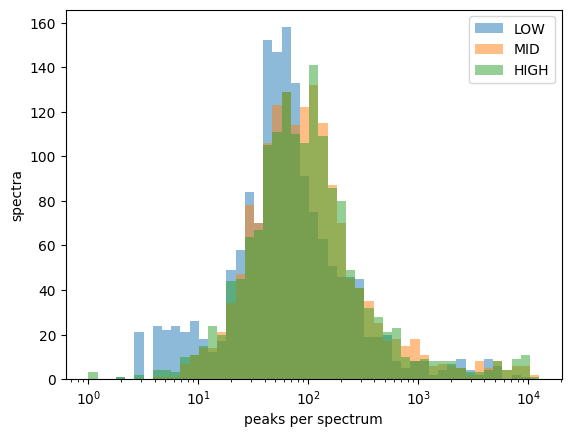

In [17]:
bins = np.logspace(0, 4.1, 50)
for energy in ["LOW", "MID", "HIGH"]:
    plt.hist(df[df.energy == energy].n_peaks, bins=bins, alpha=0.5, label=energy)
plt.xscale("log")
plt.xlabel("peaks per spectrum")
plt.ylabel("spectra")
plt.legend()
plt.savefig("../reports/figures/before_n_peaks.png", dpi=150, bbox_inches="tight")
plt.show()

### One raw spectrum: MDMA (HIGH)

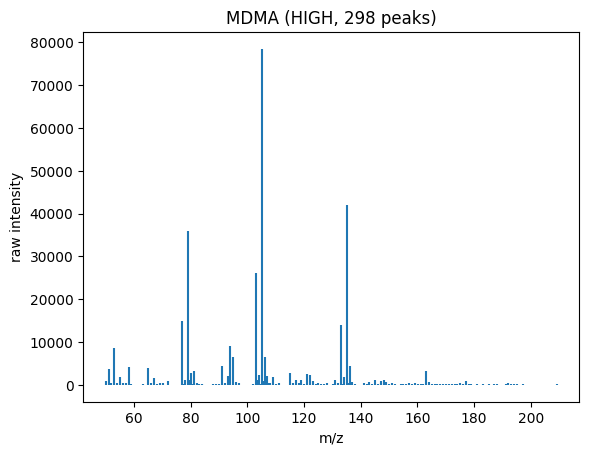

In [18]:
row = df[(df.name == "3,4-Methylenedioxymethamphetamine") & (df.energy == "HIGH")].iloc[0]
mz, intensity = row.spectrum.T
plt.vlines(mz, 0, intensity)
plt.xlabel("m/z")
plt.ylabel("raw intensity")
plt.title(f"MDMA (HIGH, {row.n_peaks} peaks)")
plt.savefig("../reports/figures/before_one_spectrum.png", dpi=150, bbox_inches="tight")
plt.show()

### Intensity range of each spectrum

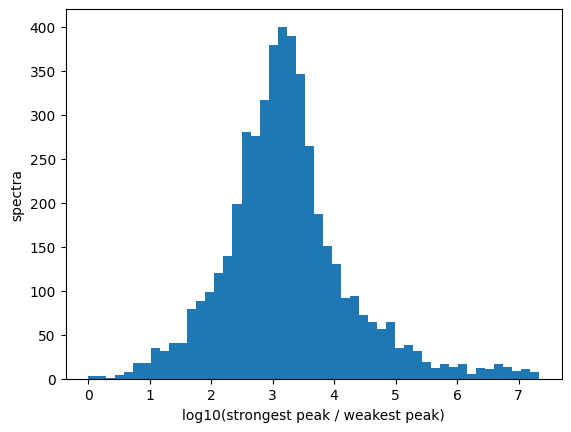

In [19]:
ratio = df.spectrum.apply(lambda s: s[:, 1].max() / s[:, 1].min())
plt.hist(np.log10(ratio), bins=50)
plt.xlabel("log10(strongest peak / weakest peak)")
plt.ylabel("spectra")
plt.savefig("../reports/figures/before_intensity_range.png", dpi=150, bbox_inches="tight")
plt.show()

## Clean the spectra
For each spectrum:
1. Divide intensities by the strongest peak, so they run from 0 to 1.
2. Drop peaks under 0.5% of the strongest (noise).
3. Keep the 200 strongest peaks.
4. Take the square root of the intensities, so small peaks count more.

In [20]:
def clean_spectrum(spectrum):
    mz, intensity = spectrum.T
    intensity = intensity / intensity.max()
    keep = intensity >= 0.005
    mz, intensity = mz[keep], intensity[keep]
    top = np.sort(np.argsort(intensity)[-200:])
    return np.column_stack([mz[top], np.sqrt(intensity[top])])

In [21]:
df["clean"] = df.spectrum.apply(clean_spectrum)

### Peaks per spectrum after cleaning

In [22]:
df.clean.str.len().groupby(df.energy).describe()

,count,mean,std,min,25%,50%,75%,max
energy,,,,,,,,
HIGH,1587.0,57.807813,43.116900,1.0,29.0,45.0,71.0,200.0
LOW,1587.0,28.538752,19.851059,2.0,17.0,26.0,35.0,200.0
MID,1587.0,43.711405,30.995361,4.0,24.0,35.0,53.0,200.0


## Normalize each level
A spectrum with many peaks gives a longer vector than one with few. Each spectrum (one level of one compound) is divided by its own length, so that every level has length 1.

### Length of each spectrum before

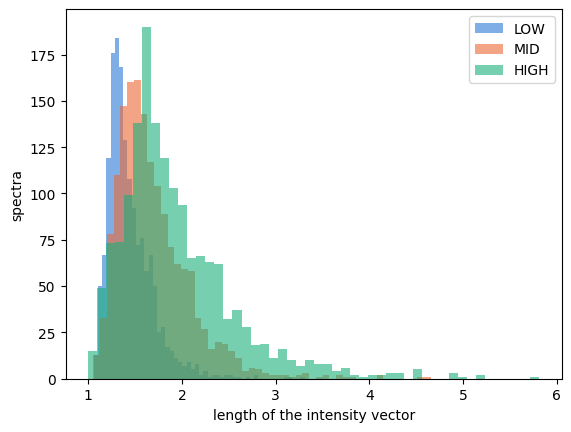

In [23]:
colors = {"LOW": "#2a78d6", "MID": "#eb6834", "HIGH": "#1baf7a"}
length = df.clean.apply(lambda s: np.linalg.norm(s[:, 1]))
for energy, color in colors.items():
    plt.hist(length[df.energy == energy], bins=50, alpha=0.6, color=color, label=energy)
plt.xlabel("length of the intensity vector")
plt.ylabel("spectra")
plt.legend()
plt.savefig("../reports/figures/before_spectrum_length.png", dpi=150, bbox_inches="tight")
plt.show()

### Divide each spectrum by its length

In [24]:
def normalize_spectrum(spectrum):
    mz, intensity = spectrum.T
    return np.column_stack([mz, intensity / np.linalg.norm(intensity)])

In [25]:
df["clean"] = df.clean.apply(normalize_spectrum)

### Check: every spectrum has length 1

In [26]:
df.clean.apply(lambda s: np.linalg.norm(s[:, 1])).describe()

count    4.761000e+03
mean     1.000000e+00
std      1.023449e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: clean, dtype: float64

## Plots after cleaning

### Peaks per spectrum

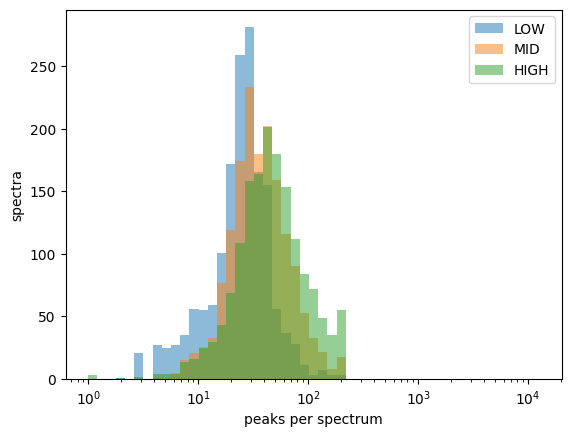

In [27]:
bins = np.logspace(0, 4.1, 50)
for energy in ["LOW", "MID", "HIGH"]:
    plt.hist(df[df.energy == energy].clean.str.len(), bins=bins, alpha=0.5, label=energy)
plt.xscale("log")
plt.xlabel("peaks per spectrum")
plt.ylabel("spectra")
plt.legend()
plt.savefig("../reports/figures/after_n_peaks.png", dpi=150, bbox_inches="tight")
plt.show()

### One cleaned spectrum: MDMA (HIGH)

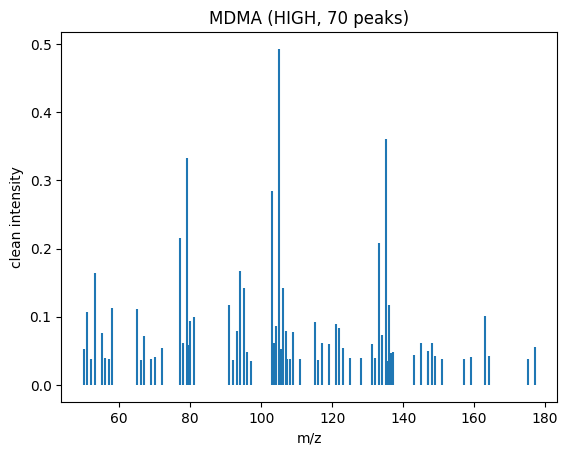

In [28]:
row = df[(df.name == "3,4-Methylenedioxymethamphetamine") & (df.energy == "HIGH")].iloc[0]
mz, intensity = row.clean.T
plt.vlines(mz, 0, intensity)
plt.xlabel("m/z")
plt.ylabel("clean intensity")
plt.title(f"MDMA (HIGH, {len(row.clean)} peaks)")
plt.savefig("../reports/figures/after_one_spectrum.png", dpi=150, bbox_inches="tight")
plt.show()

### Intensity range of each spectrum

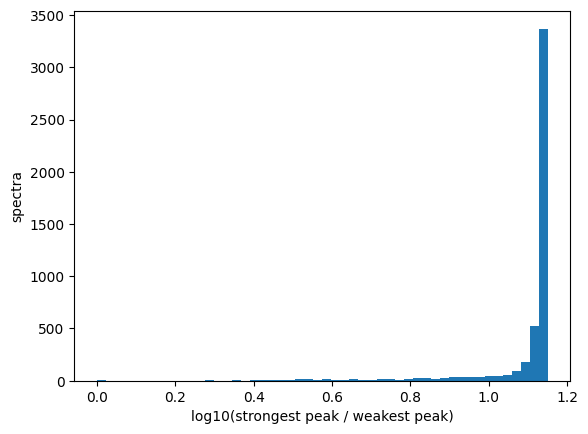

In [29]:
ratio = df.clean.apply(lambda s: s[:, 1].max() / s[:, 1].min())
plt.hist(np.log10(ratio), bins=50)
plt.xlabel("log10(strongest peak / weakest peak)")
plt.ylabel("spectra")
plt.savefig("../reports/figures/after_intensity_range.png", dpi=150, bbox_inches="tight")
plt.show()

## Bin the spectra
Each spectrum becomes a vector of 650 values: one per 1 Da bin of m/z, from 0 to 649. If several peaks fall in the same bin, the strongest one is kept. Peaks at m/z 650 or more are dropped.

In [30]:
def bin_spectrum(spectrum, n_bins=650):
    vector = np.zeros(n_bins)
    mz, intensity = spectrum.T
    bins = mz.astype(int)
    keep = bins < n_bins
    np.maximum.at(vector, bins[keep], intensity[keep])
    return vector

In [31]:
df["binned"] = df.clean.apply(bin_spectrum)
df.binned.iloc[0].shape

(650,)

In [32]:
df.head()

,name,energy,inchikey,formula,mw,exact_mass,precursor_mz,n_peaks,peaks,synonyms,mol,ion_mode,precursor_type,collision_gas,spectrum,clean,binned
0,4-Phenylmethamphetamine,LOW,LQZHCIPFXVLYCQ-UHFFFAOYSA-N,C16H19N1,225,225.1517,226.1596,9,"167.0881 1215721.6713 """" \n183.0828 722736.995...","N,.alpha.-dimethyl-[1,1′-biphenyl]-4-ethanamin...",<rdkit.Chem.rdchem.Mol object at 0x7ad86e32f140>,Positive,[M+H]+,He,"[[167.0881, 1215721.6713], [183.0828, 722736.9...","[[167.0881, 0.08616302088403685], [183.0828, 0...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
1,4-Phenylmethamphetamine,MID,LQZHCIPFXVLYCQ-UHFFFAOYSA-N,C16H19N1,225,225.1517,226.1596,16,"153.0728 638359.1431 """" \n155.0884 797639.0622...","N,.alpha.-dimethyl-[1,1′-biphenyl]-4-ethanamin...",<rdkit.Chem.rdchem.Mol object at 0x7ad846538a50>,Positive,[M+H]+,He,"[[153.0728, 638359.1431], [155.0884, 797639.06...","[[153.0728, 0.05951408595612572], [155.0884, 0...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
2,4-Phenylmethamphetamine,HIGH,LQZHCIPFXVLYCQ-UHFFFAOYSA-N,C16H19N1,225,225.1517,226.1596,18,"115.0555 610280.513 """" \n152.0651 5888619.5075...","N,.alpha.-dimethyl-[1,1′-biphenyl]-4-ethanamin...",<rdkit.Chem.rdchem.Mol object at 0x7ad846538900>,Positive,[M+H]+,He,"[[115.0555, 610280.513], [152.0651, 5888619.50...","[[115.0555, 0.06447440629523189], [152.0651, 0...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
3,"1-(1,3-Diphenylpropan-2-yl)pyrrolidine",LOW,VQECHRQHFMUVRS-UHFFFAOYSA-N,C19H23N1,265,265.1830,266.1909,87,"91.0579 59401.9811 """" \n91.1335 2895.8642 """" \...","1-(1,3-diphenylpropan-2-yl)pyrrolidine LOW",<rdkit.Chem.rdchem.Mol object at 0x7ad8465382e0>,Positive,[M+H]+,He,"[[91.0579, 59401.9811], [91.1335, 2895.8642], ...","[[91.0579, 0.10592147103999666], [117.0745, 0....","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
4,"1-(1,3-Diphenylpropan-2-yl)pyrrolidine",MID,VQECHRQHFMUVRS-UHFFFAOYSA-N,C19H23N1,265,265.1830,266.1909,175,"84.0842 2177.1901 """" \n86.0636 3347.0793 """" \n...","1-(1,3-diphenylpropan-2-yl)pyrrolidine MID",<rdkit.Chem.rdchem.Mol object at 0x7ad846538350>,Positive,[M+H]+,He,"[[84.0842, 2177.1901], [86.0636, 3347.0793], [...","[[90.8088, 0.04404752270939473], [90.9236, 0.0...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."


## Build the compound matrix
One row per compound (index = `inchikey`). Columns: `LOW_0` ... `LOW_649`, `MID_0` ... `MID_649`, `HIGH_0` ... `HIGH_649` (the binned spectra), then `precursor_mz` divided by 650.

### Keep one record per compound and energy
17 compounds have two records under different IDs; keep the first.

In [33]:
unique = df.drop_duplicates(["inchikey", "energy"])

### One table of bins per energy, joined side by side

In [34]:
tables = []
for energy in ["LOW", "MID", "HIGH"]:
    rows = unique[unique.energy == energy].set_index("inchikey")
    tables.append(pd.DataFrame(rows.binned.tolist(), index=rows.index).add_prefix(energy + "_"))

X = pd.concat(tables, axis=1)

### Add the precursor m/z

In [35]:
X["precursor_mz"] = unique.groupby("inchikey").precursor_mz.first() / 650
X.shape

(1570, 1951)

### Look at the matrix

In [36]:
X.columns

Index(['LOW_0', 'LOW_1', 'LOW_2', 'LOW_3', 'LOW_4', 'LOW_5', 'LOW_6', 'LOW_7',
       'LOW_8', 'LOW_9',
       ...
       'HIGH_641', 'HIGH_642', 'HIGH_643', 'HIGH_644', 'HIGH_645', 'HIGH_646',
       'HIGH_647', 'HIGH_648', 'HIGH_649', 'precursor_mz'],
      dtype='object', length=1951)

In [37]:
X[["LOW_100", "LOW_135", "MID_135", "HIGH_135", "precursor_mz"]].head()

,LOW_100,LOW_135,MID_135,HIGH_135,precursor_mz
inchikey,,,,,
LQZHCIPFXVLYCQ-UHFFFAOYSA-N,0.0,0.0,0.000000,0.000000,0.347938
VQECHRQHFMUVRS-UHFFFAOYSA-N,0.0,0.0,0.000000,0.000000,0.409524
KITIJFNTLBMYQD-UHFFFAOYSA-N,0.0,0.0,0.000000,0.000000,0.364862
UFRAAIGOXGTHQX-UHFFFAOYSA-N,0.0,0.0,0.112067,0.149866,0.330885
VNZLQLYBRIOLFZ-UHFFFAOYSA-N,0.0,0.0,0.094688,0.169330,0.297129


## Save
- `X.csv` is the matrix
- `compounds.csv` has the name, formula and structure (SMILES) of each compound, in the same row order. 
- `peaks.csv` has the cleaned peaks of every spectrum with their exact m/z, one row per peak.

In [38]:
compounds = unique.drop_duplicates("inchikey").set_index("inchikey").loc[X.index]
compounds["smiles"] = compounds.mol.apply(Chem.MolToSmiles)

X.to_csv("../data/processed/X.csv")
compounds[["name", "formula", "precursor_mz", "smiles"]].to_csv("../data/processed/compounds.csv")

peaks = pd.concat([
    pd.DataFrame({"inchikey": row.inchikey, "energy": row.energy, "mz": row.clean[:, 0], "intensity": row.clean[:, 1]})
    for row in unique.itertuples()
])
peaks.to_csv("../data/processed/peaks.csv", index=False)